# Gene over/under expression for succinate production in *E. coli*

This example searches for changes in gene expression that make the *E. coli* core model secrete succinate. A `GOUProblem` assigns an expression level to a few genes; MEWpy translates the levels into reaction bounds through the gene-protein-reaction (GPR) rules. An evolutionary algorithm (NSGA-II) searches the space of modifications with two objectives, BPCY and WYIELD (defined below).

The optimizations use small settings (population size and number of generations) so that the notebook runs in a few minutes. Real designs need many more evaluations, and the solutions found here are examples of what the method returns, not optimal designs.

In [1]:
import logging
import warnings

import pandas as pd
from cobra.io import read_sbml_model

import mewpy
from mewpy.optimization import EA
from mewpy.optimization.evaluation import BPCY, WYIELD
from mewpy.problems import GKOProblem, GOUProblem
from mewpy.simulation import get_simulator

# MEWpy logs the fitness statistics of each generation at INFO level; jMetalPy logs at DEBUG level by default.
mewpy.configure_logging("INFO")
logging.getLogger("jmetal").setLevel(logging.WARNING)
# Candidates that make the model infeasible are expected during the search (they get the worst fitness).
warnings.filterwarnings("ignore", message="Solver status is 'infeasible'")

## Model, medium and wild type

The model is loaded with COBRApy. The medium allows the uptake of up to 10 mmol/gDW/h of glucose and 20 mmol/gDW/h of oxygen (uptake fluxes are negative).

In [2]:
model = read_sbml_model('models/ec/e_coli_core.xml.gz')

BIOMASS_ID = 'BIOMASS_Ecoli_core_w_GAM'
PRODUCT_ID = 'EX_succ_e'
GLC = 'EX_glc__D_e'
O2 = 'EX_o2_e'
medium = {GLC: (-10, 1000), O2: (-20, 1000)}

sim = get_simulator(model, envcond=medium)
sim.find([BIOMASS_ID, PRODUCT_ID, GLC, O2])[['name', 'lb', 'ub']]

,name,lb,ub
id,,,
BIOMASS_Ecoli_core_w_GAM,Biomass Objective Function with GAM,0.0,1000.0
EX_glc__D_e,D-Glucose exchange,-10.0,1000.0
EX_o2_e,O2 exchange,-20.0,1000.0
EX_succ_e,Succinate exchange,0.0,1000.0


`get_simulator` writes the medium into the model's bounds, as the oxygen lower bound above shows. In the wild type, the parsimonious FBA (pFBA) solution grows without secreting succinate, and flux variability analysis (FVA, at 90% of the maximal growth by default) shows that succinate secretion is possible but not required:

In [3]:
wild_type = sim.simulate(method='pFBA')
print('growth: %.4f 1/h, succinate: %.4f mmol/gDW/h' % (wild_type.fluxes[BIOMASS_ID], wild_type.fluxes[PRODUCT_ID]))
sim.FVA(reactions=[PRODUCT_ID])

growth: 0.8318 1/h, succinate: 0.0000 mmol/gDW/h


{'EX_succ_e': [0.0, 2.3864760127302613]}

## Objectives

- `BPCY(BIOMASS_ID, PRODUCT_ID, method='lMOMA')`: the biomass-product coupled yield, here the product of the growth rate and the succinate flux (no substrate uptake reaction is given, so it is not divided by the uptake). The fluxes come from linear MOMA (lMOMA), which predicts the mutant's fluxes as those closest (sum of absolute differences) to the wild-type pFBA fluxes.
- `WYIELD(BIOMASS_ID, PRODUCT_ID)`: the weighted yield, 0.3 × maximum + 0.7 × minimum succinate flux over the flux distributions that keep at least 99% of the mutant's maximal growth (FBA). Candidates that grow less than 10% of the wild type score 0. Only the minimum term rewards growth-coupled production, where the cell must secrete succinate to grow near its maximum.

Both objectives are maximised, and a candidate that cannot be simulated (for example, an infeasible model) gets the worst fitness, 0.

In [4]:
def objectives():
    return [BPCY(BIOMASS_ID, PRODUCT_ID, method='lMOMA'), WYIELD(BIOMASS_ID, PRODUCT_ID)]

## The gene over/under expression problem

Each modification is a pair (gene, level). The levels are fold changes of the gene's expression: 0 deletes the gene, values below 1 under-express it and values above 1 over-express it. A reaction's level is obtained from its GPR rule (minimum over the genes of an `and`, maximum over the genes of an `or`). Level 0 closes the reaction, a level below 1 caps its flux at that fraction of its wild-type pFBA flux, and a level above 1 forces at least that multiple; reactions without wild-type flux are only affected by deletions. Genes that only catalyse transport reactions are not targets. Candidates have 2 to 6 modifications.

In [5]:
problem = GOUProblem(model, objectives(), envcond=medium, candidate_min_size=2, candidate_max_size=6)
print('targets:', len(problem.target_list), 'genes')
print('levels:', problem.levels)

targets: 114 genes
levels: [0, 0.03125, 0.0625, 0.125, 0.25, 0.5, 2, 4, 8, 16, 32]


## Optimization

The EA runs 20 generations of 50 candidates (1000 evaluations). EAs are stochastic, so each run can return different solutions; the results discussed below are those of this run. `seed` sets the EA's random choices. `mp=False` evaluates the candidates in this process, which is fast enough for this small model; the default, `mp=True`, evaluates them in parallel worker processes.

By default, `run()` returns the final population without duplicates, after simplifying each solution, that is, after removing every modification that does not change its fitness. It can contain dominated solutions.

In [6]:
ea = EA(problem, max_generations=20, population_size=50, mp=False, seed=42)
final_pop = ea.run()

[2026-11-09 23:20:45] [mewpy.optimization.jmetal.ea] [INFO] Running NSGAII


[2026-11-09 23:20:48] [mewpy] [INFO] Eval(s)|     Worst      Best    Median   Average   Std Dev|     Worst      Best    Median   Average   Std Dev|
     50|  -0.000000  2.133080  0.000000  0.080415  0.386940|  0.000000  3.029122  0.077604  0.115265  0.418999|


[2026-11-09 23:20:52] [mewpy] [INFO]     100|  -0.000000  2.133080  0.000000  0.248549  0.646386|  0.059034  3.029122  0.103086  0.159367  0.410337|


[2026-11-09 23:20:56] [mewpy] [INFO]     150|  0.000000  2.353978  0.084221  0.764753  0.972531|  0.083468  3.029122  0.105455  0.172936  0.408990|


[2026-11-09 23:21:00] [mewpy] [INFO]     200|  0.000000  2.363951  2.050021  1.638001  0.813701|  0.091223  3.029122  0.138564  0.313813  0.683836|


[2026-11-09 23:21:03] [mewpy] [INFO]     250|  0.000000  2.363951  2.050021  1.742252  0.791934|  0.138564  3.029122  0.139713  0.618059  1.051214|


... (11 outputs left out)

[2026-11-09 23:21:56] [mewpy] [INFO]     850|  0.000000  2.375157  1.321664  1.330637  0.710923|  0.256057  3.770732  2.681109  2.355204  1.116155|


[2026-11-09 23:22:00] [mewpy] [INFO]     900|  0.000000  2.375157  1.321664  1.354929  0.712169|  0.256057  3.770732  2.681109  2.318583  1.114873|


[2026-11-09 23:22:04] [mewpy] [INFO]     950|  0.000000  2.375157  1.321664  1.362290  0.720512|  0.256057  3.770732  2.681109  2.294563  1.145618|


[2026-11-09 23:22:09] [mewpy] [INFO]    1000|  0.000000  2.375157  1.321664  1.394354  0.729149|  0.256057  3.770732  2.681109  2.233855  1.171319|


In [7]:
df = ea.dataframe()
df.sort_values('BPCY', ascending=False)

,Modification,Size,BPCY,WYIELD
3,"{'b2029': 0.25, 'b0721': 0.0625}",2,2.375157,0.256057
4,"{'b2029': 0.25, 'b0721': 0.125}",2,2.354628,0.259415
0,"{'b2029': 4, 'b0720': 0.125}",2,1.986574,1.460423
1,"{'b0720': 0.0625, 'b2029': 4}",2,1.321664,2.681109
2,"{'b0720': 0.03125, 'b2029': 4}",2,0.771976,3.291452
5,{'b0720': 0.03125},1,0.000000,3.770732


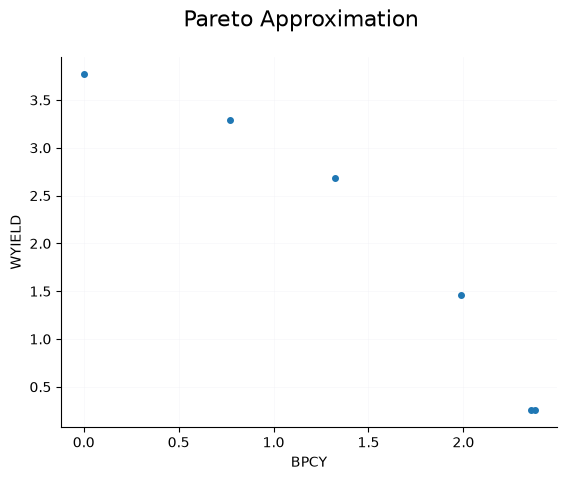

In [8]:
ea.plot()

## Inspecting the solutions

The two extremes of the population are the solution with the highest BPCY and the one with the highest WYIELD (ties broken by the other objective). For each, the first table lists the modified genes and the reactions they catalyse. The second simulates the mutant with lMOMA (the method behind BPCY) and with pFBA (maximal growth), and gives the succinate range over the flux distributions with at least 99% of the mutant's maximal growth (the range behind WYIELD).

In [9]:
def describe(solution):
    rows = []
    for gene, level in solution.values.items():
        rows.append({'gene': gene, 'level': level, 'reactions': ', '.join(sim.get_gene(gene).reactions)})
    return pd.DataFrame(rows)


def phenotype(solution):
    rows = {}
    for method in ['lMOMA', 'pFBA']:
        res = problem.simulate(solution=solution.values, method=method)
        rows[method] = {'growth': res.fluxes[BIOMASS_ID], 'succinate': res.fluxes[PRODUCT_ID]}
    return pd.DataFrame(rows).T


def succinate_range(solution):
    # FVA over the flux distributions with at least 99% of the mutant's maximal growth
    return problem.FVA(reactions=[PRODUCT_ID], solution=solution.values, obj_frac=0.99)[PRODUCT_ID]


best = {'BPCY': max(final_pop, key=lambda s: (s.fitness[0], s.fitness[1])),
        'WYIELD': max(final_pop, key=lambda s: (s.fitness[1], s.fitness[0]))}
for name, solution in best.items():
    print('Highest %s: BPCY = %.4f, WYIELD = %.4f' % (name, solution.fitness[0], solution.fitness[1]))
    display(describe(solution))
    display(phenotype(solution))
    print('succinate range at >= 99%% of maximal growth: [%.4f, %.4f]' % tuple(succinate_range(solution)))

Highest BPCY: BPCY = 2.3752, WYIELD = 0.2561


,gene,level,reactions
0,b2029,0.2500,GND
1,b0721,0.0625,SUCDi


,growth,succinate
lMOMA,0.439488,5.404373
pFBA,0.644686,0.000000


succinate range at >= 99% of maximal growth: [0.0000, 0.8535]
Highest WYIELD: BPCY = 0.0000, WYIELD = 3.7707


,gene,level,reactions
0,b0720,0.03125,CS


,growth,succinate
lMOMA,0.135213,0.0
pFBA,0.135077,0.0


succinate range at >= 99% of maximal growth: [0.0000, 12.5691]


BPCY is the product of the lMOMA growth and succinate fluxes (0.4395 × 5.4044 = 2.3752 for the first solution). The first solution caps succinate dehydrogenase (SUCDi, gene b0721) at 1/16 and phosphogluconate dehydrogenase (GND, gene b2029) at 1/4 of their wild-type fluxes. The second caps citrate synthase (CS, gene b0720) at 1/32 of its wild-type flux; lMOMA predicts no succinate secretion for it, so its BPCY is 0.

Neither mutant secretes succinate at maximal growth (pFBA), and the minimum of their succinate range at 99% of maximal growth is 0. Production is possible near maximal growth but not required, so their WYIELD comes only from the maximum term (0.3 × 0.8535 = 0.2561 and 0.3 × 12.5691 = 3.7707).

## Knockouts only

A `GKOProblem` with the same objectives and medium only deletes genes. It excludes essential genes from the targets (the progress bar below is that essentiality analysis). The EA runs with the same settings.

In [10]:
ko_problem = GKOProblem(model, objectives(), envcond=medium, candidate_min_size=2, candidate_max_size=6)
ko_ea = EA(ko_problem, max_generations=20, population_size=50, mp=False, seed=42)
ko_pop = ko_ea.run()
ko_df = ko_ea.dataframe()
ko_df.sort_values('BPCY', ascending=False)

[2026-11-09 23:22:22] [mewpy.problems.genes] [INFO] Building modification target list.


  0%|          | 0/137 [00:00<?, ?it/s]

100%|██████████| 137/137 [00:00<00:00, 2277.44it/s]


[2026-11-09 23:22:22] [mewpy.optimization.jmetal.ea] [INFO] Running NSGAII


[2026-11-09 23:22:27] [mewpy] [INFO] Eval(s)|     Worst      Best    Median   Average   Std Dev|     Worst      Best    Median   Average   Std Dev|
     50|  -0.000000  2.207688  0.000000  0.048837  0.309235|  0.000000  0.223220  0.047415  0.061756  0.043236|


[2026-11-09 23:22:31] [mewpy] [INFO]     100|  -0.000000  2.320761  0.000000  0.100977  0.443121|  0.047415  0.223220  0.103086  0.092508  0.029916|


... (15 outputs left out)

[2026-11-09 23:23:35] [mewpy] [INFO]     900|  1.146490  2.345225  1.555444  1.675714  0.318172|  0.244830  6.098155  5.691000  4.375513  2.309532|


[2026-11-09 23:23:39] [mewpy] [INFO]     950|  1.146490  2.345225  1.555444  1.676261  0.338264|  0.244830  6.098155  5.691000  4.471427  2.196951|


[2026-11-09 23:23:43] [mewpy] [INFO]    1000|  1.146490  2.345225  1.555444  1.671189  0.361320|  0.244830  6.098155  5.691000  4.318533  2.207088|


,Modification,Size,BPCY,WYIELD
2,"{'b0722': 0, 'b2029': 0}",2,2.345225,0.244830
4,"{'b0722': 0, 'b0767': 0}",2,2.345225,0.244830
7,"{'b1602': 0, 'b0722': 0, 'b3236': 0, 'b2029': 0}",4,2.258074,2.097919
5,"{'b2463': 0, 'b1602': 0, 'b0767': 0, 'b0722': 0}",4,1.908915,2.117919
6,"{'b1602': 0, 'b2463': 0, 'b0722': 0, 'b2029': 0}",4,1.908915,2.117919
9,"{'b1602': 0, 'b0767': 0, 'b0722': 0}",3,1.908915,0.549660
10,"{'b2463': 0, 'b1602': 0, 'b0767': 0, 'b0474': ...",5,1.908915,2.106534
0,"{'b0114': 0, 'b0722': 0, 'b2029': 0}",3,1.555444,5.691000
1,"{'b0114': 0, 'b0767': 0, 'b0722': 0}",3,1.555444,5.691000
3,"{'b1602': 0, 'b0114': 0, 'b0722': 0, 'b2029': 0}",4,1.146490,6.098155


In [11]:
pd.DataFrame({
    'targets': [len(problem.target_list), len(ko_problem.target_list)],
    'solutions': [len(df), len(ko_df)],
    'best BPCY': [df['BPCY'].max(), ko_df['BPCY'].max()],
    'best WYIELD': [df['WYIELD'].max(), ko_df['WYIELD'].max()],
}, index=['GOUProblem', 'GKOProblem'])

,targets,solutions,best BPCY,best WYIELD
GOUProblem,114,6,2.375157,3.770732
GKOProblem,109,11,2.345225,6.098155


Every KO candidate is also an OU candidate (deletion is level 0, and the KO targets are the OU targets minus the essential genes). In this run, the KO search nevertheless ended with the higher best WYIELD (6.098 against 3.771) and a slightly lower best BPCY (2.345 against 2.375), which shows how far from optimal the OU front of this short run is.

## The same problem on a REFRAMED model

REFRAMED prefixes the SBML ids (`R_` for reactions, `G_` for genes), but MEWpy problems accept ids with or without the prefix and report the backend's native ids. Below, the problem is defined on a REFRAMED model with the same unprefixed ids, and the two solutions inspected above are evaluated on it.

The wild-type pFBA fluxes are the reference for the OU bounds and for lMOMA. MEWpy's COBRApy and REFRAMED simulators both run pFBA keeping 99.9% of the optimal growth, and the two wild-type growth rates printed below agree. So do the fitness values, both with the REFRAMED problem's own reference and with the COBRApy reference fluxes, keyed by unprefixed ids, given through `reference=`.

In [12]:
from reframed.io.sbml import load_cbmodel

r_model = load_cbmodel('models/ec/e_coli_core.xml.gz')
r_wild_type = get_simulator(r_model, envcond=medium).simulate(method='pFBA')
print('wild-type pFBA growth: COBRApy %.6f, REFRAMED %.6f'
      % (wild_type.fluxes[BIOMASS_ID], r_wild_type.fluxes['R_' + BIOMASS_ID]))  # REFRAMED fluxes use native ids

r_problem = GOUProblem(r_model, objectives(), envcond=medium, candidate_min_size=2, candidate_max_size=6)
r_problem_ref = GOUProblem(r_model, objectives(), envcond=medium, reference=wild_type.fluxes,
                           candidate_min_size=2, candidate_max_size=6)

rows = {}
for name, solution in best.items():
    candidate = r_problem.encode(solution.values)  # the unprefixed gene ids are resolved to 'G_...'
    print('highest %s, decoded by the REFRAMED problem:' % name, r_problem.decode(candidate))
    rows['highest ' + name] = {
        'COBRApy': solution.fitness,
        'REFRAMED': r_problem.evaluate_solution(candidate),
        'REFRAMED, COBRApy reference': r_problem_ref.evaluate_solution(candidate),
    }
pd.DataFrame(rows).T.map(lambda f: '[%.6f, %.6f]' % tuple(f))

wild-type pFBA growth: COBRApy 0.831781, REFRAMED 0.831781
highest BPCY, decoded by the REFRAMED problem: {'G_b2029': 0.25, 'G_b0721': 0.0625}
highest WYIELD, decoded by the REFRAMED problem: {'G_b0720': 0.03125}


,COBRApy,REFRAMED,"REFRAMED, COBRApy reference"
highest BPCY,"[2.375157, 0.256057]","[2.375157, 0.256057]","[2.375157, 0.256057]"
highest WYIELD,"[0.000000, 3.770732]","[0.000000, 3.770732]","[0.000000, 3.770732]"
